# ChestScan AI: chest X-ray classification

This notebook keeps the original beginner-style workflow and compares three experiments: the custom CNN, MobileNetV2 Transfer Learning, and MobileNetV2 Fine-tuning. The custom CNN architecture is based on the original notebook, which remains preserved in `original_notebook_backup.ipynb`.

The stored custom-CNN result was 0.8109 test accuracy at threshold 0.5. The notebook later changed the threshold using validation data and then evaluated the test set again, reporting 0.8365. Since the same test set was inspected repeatedly, these are historical experiments, not an unbiased final result. The new workflow chooses the MobileNetV2 model and threshold using validation data, compares all three models on the test split, and tracks each model in MLflow. A truly independent final test would need new data.

## 1. Imports and settings

These are the libraries and values used in the notebook. A fixed random seed helps make the data split repeatable.

In [26]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import kagglehub
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

IMG_SIZE = (180, 180)
MOBILENET_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
CLASSES = ["NORMAL", "PNEUMONIA"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "models").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
TRANSFER_MODEL_PATH = MODEL_DIR / "mobilenetv2_transfer_offline_augmented_best.keras"
FINETUNE_MODEL_PATH = MODEL_DIR / "mobilenetv2_finetune_offline_augmented_best.keras"
CUSTOM_CNN_MODEL_PATH = MODEL_DIR / "custom_cnn_offline_augmented_best.keras"


## 2. Dataset folders

The Kaggle dataset used in the original notebook has `train`, `val`, and `test` folders. This cell uses the same KaggleHub download. It does not train a model; the download happens only if you run this cell.

In [27]:
dataset_path = Path(
    kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
)

data_path = dataset_path / "chest_xray"
if not (data_path / "train").is_dir():
    data_path = data_path / "chest_xray"

if not (data_path / "train").is_dir() or not (data_path / "test").is_dir():
    raise FileNotFoundError(
        f"Could not find train and test folders under {dataset_path}"
    )

print("Dataset folder:", data_path)
print("Label mapping:", {name: index for index, name in enumerate(CLASSES)})


Dataset folder: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray
Label mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


## 3. Count and load the images

The old validation folder contains only 16 images, so it is too small for reliable validation. We combine the original training and validation images, then create a stratified 80/20 split. The official test folder is kept out of training and threshold selection. Images stay grayscale at 180-by-180 here, matching the original custom-CNN preprocessing.

In [28]:
def load_images(split):
    images = []
    labels = []

    for label, class_name in enumerate(CLASSES):
        class_path = data_path / split / class_name
        if not class_path.is_dir():
            raise FileNotFoundError(f"Missing folder: {class_path}")

        image_paths = sorted(
            path for path in class_path.rglob("*")
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )
        print(f"{split} / {class_name}: {len(image_paths)} images")

        for image_path in image_paths:
            with Image.open(image_path) as image:
                image = image.convert("L")
                image = image.resize(IMG_SIZE)
                images.append(np.asarray(image, dtype=np.float32))
                labels.append(label)

    images = np.asarray(images, dtype=np.float32) / 255.0
    images = images[..., np.newaxis]
    return images, np.asarray(labels, dtype=np.int32)

X_train_original, y_train_original = load_images("train")
X_test, y_test = load_images("test")

if (data_path / "val").is_dir():
    X_val_original, y_val_original = load_images("val")
    X_all = np.concatenate([X_train_original, X_val_original], axis=0)
    y_all = np.concatenate([y_train_original, y_val_original], axis=0)
else:
    X_all = X_train_original
    y_all = y_train_original

X_train, X_val, y_train, y_val = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all,
)

print("\nTrain:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


train / NORMAL: 1341 images
train / PNEUMONIA: 3875 images
test / NORMAL: 234 images
test / PNEUMONIA: 390 images
val / NORMAL: 8 images
val / PNEUMONIA: 8 images

Train: (4185, 180, 180, 1) (4185,)
Validation: (1047, 180, 180, 1) (1047,)
Test: (624, 180, 180, 1) (624,)


In [29]:
# Count the classes in the training set
normal_count = np.sum(y_train == 0)
pneumonia_count = np.sum(y_train == 1)

print("NORMAL images:", normal_count)
print("PNEUMONIA images:", pneumonia_count)

# Number of additional NORMAL images needed to balance the classes
num_to_generate = max(0, int(pneumonia_count - normal_count))

print("NORMAL images to generate:", num_to_generate)

NORMAL images: 1079
PNEUMONIA images: 3106
NORMAL images to generate: 2027


In [30]:
# Augmentation transformations
offline_augmenter = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03
    ),
    layers.RandomContrast(0.10),
])

augmented_normal_images = []

AUGMENT_BATCH_SIZE = 32

# Get only NORMAL images from the training set
X_train_normal = X_train[y_train == 0]

for start in range(0, num_to_generate, AUGMENT_BATCH_SIZE):
    current_batch_size = min(
        AUGMENT_BATCH_SIZE,
        num_to_generate - start
    )

    # Randomly select NORMAL images
    indices = np.random.randint(
        0,
        len(X_train_normal),
        size=current_batch_size
    )

    images_batch = tf.convert_to_tensor(
        X_train_normal[indices],
        dtype=tf.float32
    )

    # Create new transformed images
    augmented_batch = offline_augmenter(
        images_batch,
        training=True
    )

    # Keep pixel values within [0, 1]
    augmented_batch = tf.clip_by_value(
        augmented_batch,
        0.0,
        1.0
    )

    augmented_normal_images.append(augmented_batch.numpy())

# Combine the generated batches
if augmented_normal_images:
    X_augmented_normal = np.concatenate(
        augmented_normal_images,
        axis=0
    )
else:
    X_augmented_normal = np.empty(
        (0, *X_train.shape[1:]),
        dtype=np.float32
    )

print("Generated NORMAL images:", len(X_augmented_normal))
print("Shape:", X_augmented_normal.shape)

Generated NORMAL images: 2027
Shape: (2027, 180, 180, 1)


In [31]:
# All generated images belong to NORMAL (label 0)
y_augmented_normal = np.zeros(
    len(X_augmented_normal),
    dtype=y_train.dtype
)

# Combine original training data with augmented NORMAL images
X_train_balanced = np.concatenate(
    [X_train, X_augmented_normal],
    axis=0
)

y_train_balanced = np.concatenate(
    [y_train, y_augmented_normal],
    axis=0
)

# Shuffle images and labels together
rng = np.random.default_rng(42)
indices = rng.permutation(len(y_train_balanced))

X_train_balanced = X_train_balanced[indices]
y_train_balanced = y_train_balanced[indices]

print("\nTraining set after augmentation:")
print("NORMAL:", np.sum(y_train_balanced == 0))
print("PNEUMONIA:", np.sum(y_train_balanced == 1))
print("Total:", len(y_train_balanced))


Training set after augmentation:
NORMAL: 3106
PNEUMONIA: 3106
Total: 6212


## 4. Prepare images for MobileNetV2

MobileNetV2 expects 224-by-224 RGB images. The original X-rays are grayscale, so we resize them, copy the grayscale channel into three channels, and use MobileNetV2's `preprocess_input` once. Training, validation, test, and single-image prediction use the same steps.

In [32]:
def prepare_for_mobilenet(X):
    X = tf.image.resize(X, MOBILENET_SIZE)
    X = tf.image.grayscale_to_rgb(X)
    X = preprocess_input(X * 255.0)
    return X

X_train_mobilenet = prepare_for_mobilenet(X_train_balanced)
X_val_mobilenet = prepare_for_mobilenet(X_val)
X_test_mobilenet = prepare_for_mobilenet(X_test)

print("MobileNet training images:", X_train_mobilenet.shape)
print("MobileNet validation images:", X_val_mobilenet.shape)
print("MobileNet test images:", X_test_mobilenet.shape)


MobileNet training images: (6212, 224, 224, 3)
MobileNet validation images: (1047, 224, 224, 3)
MobileNet test images: (624, 224, 224, 3)


## 5. Shared offline augmentation and class weights

Additional NORMAL images are generated before training and added to the training set to balance the classes. All three models use this same offline-augmented training data; validation and test images are not augmented. Class weights are calculated from the final training labels.

In [33]:
classes = np.unique(y_train_balanced)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_balanced,
)
class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}
print("Class weights:", class_weights)


Class weights: {0: 1.0, 1: 1.0}


## 6. Custom CNN with offline augmentation

This retains the original three-block CNN architecture. It trains first and uses the same offline-augmented balanced training arrays as both MobileNetV2 experiments, without additional model-specific online augmentation.

In [34]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)


custom_cnn_model = models.Sequential([
    layers.Input(shape=(180, 180, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

custom_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)
custom_cnn_model.summary()

custom_cnn_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(CUSTOM_CNN_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

custom_cnn_history = custom_cnn_model.fit(
    X_train_balanced,
    y_train_balanced,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=custom_cnn_callbacks,
)
custom_cnn_best_model = tf.keras.models.load_model(CUSTOM_CNN_MODEL_PATH)
custom_cnn_best_epoch = int(np.argmin(custom_cnn_history.history["val_loss"]))

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,022,785 (30.60 MB)

 Trainable params: 8,022,785 (30.60 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7611 - auc: 0.8345 - loss: 0.4843 - precision: 0.7907 - recall: 0.6930
Epoch 1: val_loss improved from None to 0.11740, saving model to /models/custom_cnn_offline_augmented_best.keras
195/195 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - accuracy: 0.8717 - auc: 0.9493 - loss: 0.2897 - precision: 0.8891 - recall: 0.8493 - val_accuracy: 0.9570 - val_auc: 0.9908 - val_loss: 0.1174 - val_precision: 0.9778 - val_recall: 0.9640 - learning_rate: 0.0010
Epoch 2/20
192/195 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9469 - auc: 0.9858 - loss: 0.1463 - precision: 0.9461 - recall: 0.9479
Epoch 2: val_loss did not improve from 0.11740
195/195 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9535 - auc: 0.9883 - loss: 0.1300 - precision: 0.9548 - recall: 0.9520 - val_accuracy: 0.9465 - val_auc: 0.9927 - val_loss: 0.1507 - val_precision: 0.9972 - val_recall: 0.9305 - learning_rate: 0.0010
Epoch 3/20
193/195 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/ste

## 7. Transfer Learning with MobileNetV2

ImageNet-trained MobileNetV2 starts frozen, so the first training phase learns only the new binary classification head. `ModelCheckpoint` saves the epoch with the lowest validation loss. The callback list also stops training when validation loss stops improving and reduces the learning rate when needed.

In [35]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
    name="mobilenetv2_base",
)
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)

transfer_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(TRANSFER_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

transfer_history = model.fit(
    X_train_mobilenet,
    y_train_balanced,
    validation_data=(X_val_mobilenet, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=transfer_callbacks,
    class_weight=class_weights,
)


Epoch 1/20
195/195 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9057 - auc: 0.9616 - loss: 0.2145 - precision: 0.9064 - recall: 0.9075
Epoch 1: val_loss improved from None to 0.09627, saving model to /models/mobilenetv2_transfer_offline_augmented_best.keras
195/195 ━━━━━━━━━━━━━━━━━━━━ 45s 148ms/step - accuracy: 0.9446 - auc: 0.9876 - loss: 0.1413 - precision: 0.9441 - recall: 0.9453 - val_accuracy: 0.9580 - val_auc: 0.9931 - val_loss: 0.0963 - val_precision: 0.9717 - val_recall: 0.9717 - learning_rate: 0.0010
Epoch 2/20
193/195 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9681 - auc: 0.9963 - loss: 0.0775 - precision: 0.9726 - recall: 0.9632
Epoch 2: val_loss improved from 0.09627 to 0.07937, saving model to /models/mobilenetv2_transfer_offline_augmented_best.keras
195/195 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.9709 - auc: 0.9960 - loss: 0.0758 - precision: 0.9744 - recall: 0.9672 - val_accuracy: 0.9694 - val_auc: 0.9937 - val_loss: 0.0794 - val_precision: 0.9745 - val_

## 8. Fine-tuning MobileNetV2

Fine-tuning starts by loading the best Transfer Learning checkpoint. We unfreeze only the last 30 MobileNetV2 layers and keep Batch Normalization layers frozen. The model is compiled again with a smaller learning rate. A separate checkpoint keeps the Transfer Learning model safe.

In [36]:
import tensorflow as tf
import numpy as np

def prepare_mobilenet_dataset(
    X, y, batch_size, shuffle=False,
    input_range="auto"
):
    X = np.asarray(X)
    y = np.asarray(y)

    if X.ndim == 3:
        X = X[..., np.newaxis]

    if X.shape[-1] not in (1, 3):
        raise ValueError(
            f"Expected 1 or 3 channels, got {X.shape}"
        )

    x_min = float(np.min(X))
    x_max = float(np.max(X))

    if input_range == "auto":
        if x_min < 0 and x_min >= -1.01 and x_max <= 1.01:
            input_range = "normalized"
        elif x_min >= 0 and x_max <= 1.0:
            input_range = "zero_one"
        elif x_min >= 0 and x_max <= 255.0:
            input_range = "zero_255"
        else:
            raise ValueError(
                f"Unknown image range: [{x_min}, {x_max}]"
            )

    print(
        f"Image range: [{x_min:.3f}, {x_max:.3f}] "
        f"-> {input_range}"
    )

    dataset = tf.data.Dataset.from_tensor_slices((X, y))

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=min(len(X), 2000),
            reshuffle_each_iteration=True
        )

    def preprocess(image, label):
        image = tf.cast(image, tf.float32)

        image = tf.image.resize(image, (224, 224))

        if X.shape[-1] == 1:
            image = tf.image.grayscale_to_rgb(image)

        if input_range == "zero_one":
            image = image * 255.0
            image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

        elif input_range == "zero_255":
            image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

        elif input_range == "normalized":
            # Already normalized to [-1, 1]
            pass

        else:
            raise ValueError(f"Invalid input_range: {input_range}")

        return image, label

    dataset = dataset.map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return (
        dataset
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )




In [37]:
train_dataset = prepare_mobilenet_dataset(
    X_train_balanced,
    y_train_balanced,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_dataset = prepare_mobilenet_dataset(
    X_val_mobilenet,
    y_val,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Image range: [0.000, 1.000] -> zero_one
Image range: [-1.000, 1.000] -> normalized


In [ ]:
finetune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(FINETUNE_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1,
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]


# Load trained Transfer Learning model
model_finetune = tf.keras.models.load_model(
    str(TRANSFER_MODEL_PATH)
)

# Get MobileNetV2 base model
base_model = model_finetune.get_layer("mobilenetv2_base")

# Unfreeze base model
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


model_finetune.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
    
)

finetune_history = model_finetune.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=finetune_callbacks,
    class_weight=class_weights,
)

print("Fine-tuning completed!")

Epoch 1/20


## 9. Compare the training curves

The plots show training and validation loss and accuracy for each stage. They help us see whether the model is learning and whether validation performance is getting worse.

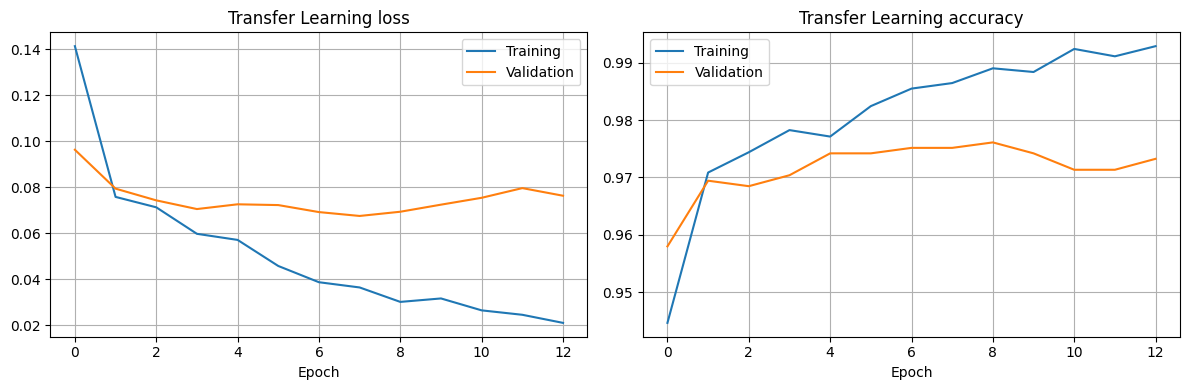

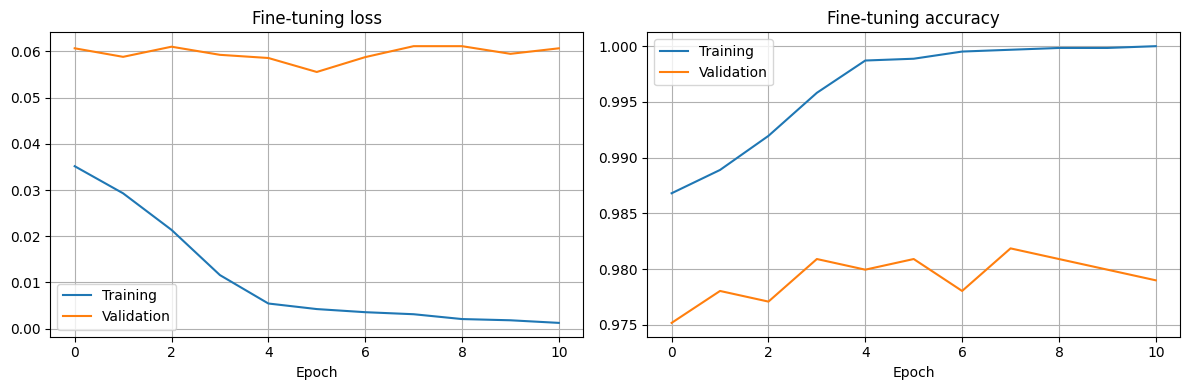

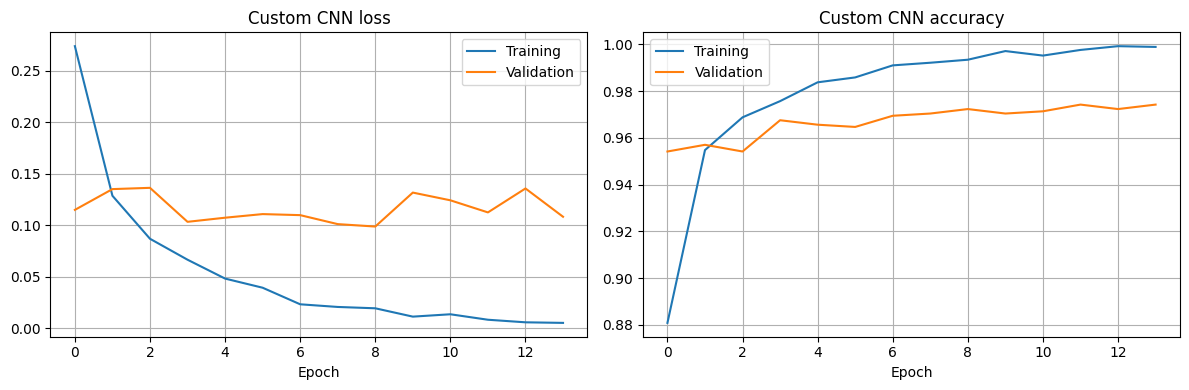

In [ ]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(title + " loss")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title(title + " accuracy")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(transfer_history, "Transfer Learning")
plot_history(finetune_history, "Fine-tuning")
plot_history(custom_cnn_history, "Custom CNN")


## 10. Load the best checkpoints and compare validation results

Saving and evaluating are different: `ModelCheckpoint` saves model weights from the best validation-loss epoch; `load_model` loads those saved weights; prediction and metrics evaluate them. Validation AUC is reported for all three models. The MobileNetV2 models are still selected independently for the downstream prediction workflow.

In [ ]:
if not TRANSFER_MODEL_PATH.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {TRANSFER_MODEL_PATH}")
if not FINETUNE_MODEL_PATH.is_file():
    raise FileNotFoundError(f"Missing checkpoint: {FINETUNE_MODEL_PATH}")

transfer_best_model = tf.keras.models.load_model(TRANSFER_MODEL_PATH)
finetune_best_model = tf.keras.models.load_model(FINETUNE_MODEL_PATH)

transfer_best_epoch = int(np.argmin(transfer_history.history["val_loss"]))
finetune_best_epoch = int(np.argmin(finetune_history.history["val_loss"]))
transfer_val_auc = transfer_history.history["val_auc"][transfer_best_epoch]
finetune_val_auc = finetune_history.history["val_auc"][finetune_best_epoch]
custom_cnn_val_auc = custom_cnn_history.history["val_auc"][custom_cnn_best_epoch]

print("Validation AUC comparison:")
for model_name, validation_auc in [
    ("Custom CNN", custom_cnn_val_auc),
    ("Transfer Learning", transfer_val_auc),
    ("Fine-tuning", finetune_val_auc),
]:
    print(f"{model_name}: {validation_auc:.4f}")

print("Transfer Learning validation AUC:", round(transfer_val_auc, 4))
print("Fine-tuning validation AUC:", round(finetune_val_auc, 4))

if finetune_val_auc > transfer_val_auc:
    best_model = finetune_best_model
    best_model_name = "fine-tuning"
    best_model_path = FINETUNE_MODEL_PATH
else:
    best_model = transfer_best_model
    best_model_name = "transfer learning"
    best_model_path = TRANSFER_MODEL_PATH

print("Selected using validation AUC:", best_model_name)


Validation AUC comparison:
Custom CNN: 0.9932
Transfer Learning: 0.9953
Fine-tuning: 0.9968
Transfer Learning validation AUC: 0.9953
Fine-tuning validation AUC: 0.9968
Selected using validation AUC: fine-tuning


## 11. Choose a threshold using validation data

The default threshold is not automatically best. We compare a few thresholds using validation precision, recall, and F1. This notebook selects the threshold with the best validation F1; a medical screening threshold needs clinical requirements and clinical validation.

In [ ]:
val_probabilities = best_model.predict(X_val_mobilenet, verbose=0).ravel()
threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]:
    val_predictions = (val_probabilities >= threshold).astype(int)
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, val_predictions, zero_division=0),
        "recall": recall_score(y_val, val_predictions, zero_division=0),
        "f1": f1_score(y_val, val_predictions, zero_division=0),
    })

for result in threshold_results:
    print(result)

selected_threshold = max(threshold_results, key=lambda result: result["f1"])["threshold"]
print("Selected validation threshold:", selected_threshold)


{'threshold': 0.3, 'precision': 0.9833759590792839, 'recall': 0.9897039897039897, 'f1': 0.986529826812059}
{'threshold': 0.4, 'precision': 0.9858429858429858, 'recall': 0.9858429858429858, 'f1': 0.9858429858429858}
{'threshold': 0.5, 'precision': 0.9883870967741936, 'recall': 0.9858429858429858, 'f1': 0.9871134020618557}
{'threshold': 0.6, 'precision': 0.9896640826873385, 'recall': 0.9858429858429858, 'f1': 0.9877498388136686}
{'threshold': 0.7, 'precision': 0.9922077922077922, 'recall': 0.9832689832689833, 'f1': 0.9877181641887525}
{'threshold': 0.8, 'precision': 0.993455497382199, 'recall': 0.9768339768339769, 'f1': 0.9850746268656716}
Selected validation threshold: 0.6


## 12. Final test evaluation

This cell reports the selected MobileNetV2 checkpoint on the test data. The next section also compares all three checkpoints at a shared 0.5 threshold. Since this test split has been inspected repeatedly, these results are exploratory and not a fully independent estimate. Do not use them to change the model or threshold.

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 313ms/step
Selected model: fine-tuning
Selected threshold: 0.6
Accuracy: 0.8381
Precision: 0.7967
Recall: 0.9949
F1: 0.8848
ROC-AUC: 0.9624

Confusion matrix (NORMAL, PNEUMONIA):
[[135  99]
 [  2 388]]

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9854    0.5769    0.7278       234
   PNEUMONIA     0.7967    0.9949    0.8848       390

    accuracy                         0.8381       624
   macro avg     0.8911    0.7859    0.8063       624
weighted avg     0.8675    0.8381    0.8259       624



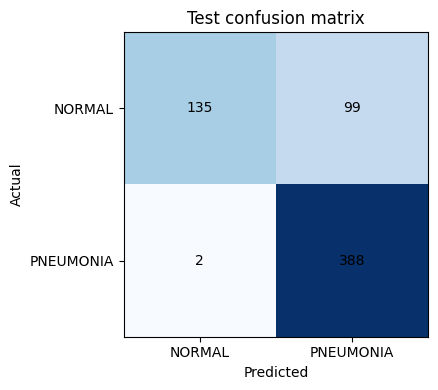

98

In [ ]:
test_probabilities = best_model.predict(X_test_mobilenet, verbose=1).ravel()
if len(test_probabilities) != len(y_test):
    raise ValueError("Test predictions and labels do not have the same length")

test_predictions = (test_probabilities >= threshold).astype(int)
test_matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])

print("Selected model:", best_model_name)
print("Selected threshold:", selected_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("F1:", round(f1_score(y_test, test_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))

print("\nConfusion matrix (NORMAL, PNEUMONIA):")
print(test_matrix)
print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=CLASSES,
    digits=4,
    zero_division=0,
))

plt.figure(figsize=(5, 4))
plt.imshow(test_matrix, cmap="Blues")
plt.xticks([0, 1], CLASSES)
plt.yticks([0, 1], CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test confusion matrix")
for row in range(2):
    for column in range(2):
        plt.text(column, row, str(test_matrix[row, column]), ha="center", va="center")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mobilenetv2_confusion_matrix.png")
plt.show()

metrics = {
    "model": best_model_name,
    "threshold": float(selected_threshold),
    "accuracy": float(accuracy_score(y_test, test_predictions)),
    "precision": float(precision_score(y_test, test_predictions, zero_division=0)),
    "recall": float(recall_score(y_test, test_predictions, zero_division=0)),
    "f1": float(f1_score(y_test, test_predictions, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, test_probabilities)),
    "confusion_matrix": test_matrix.tolist(),
}
(OUTPUT_DIR / "mobilenetv2_test_metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "selected_threshold.json").write_text(
    json.dumps({
        "checkpoint": str(best_model_path.relative_to(PROJECT_ROOT)),
        "threshold": float(0.5),
    }, indent=2),
    encoding="utf-8",
)


## 13. Compare all three models on the test set

For a direct comparison, all three checkpoints are evaluated on the same held-out test images using a 0.5 classification threshold. These results are for comparison and do not change the validation-based model or threshold selection above.

In [ ]:
test_model_candidates = [
    ("Custom CNN", custom_cnn_best_model, X_test),
    ("Transfer Learning", transfer_best_model, X_test_mobilenet),
    ("Fine-tuning", finetune_best_model, X_test_mobilenet),
]
test_model_comparison = []
custom_cnn_test_metrics = None
comparison_threshold = 0.5

for model_name, candidate_model, candidate_images in test_model_candidates:
    probabilities = candidate_model.predict(candidate_images, verbose=0).ravel()
    if len(probabilities) != len(y_test):
        raise ValueError(f"{model_name} predictions and test labels have different lengths")

    predictions = (probabilities >= comparison_threshold).astype(int)
    result = {
        "model": model_name,
        "threshold": comparison_threshold,
        "accuracy": float(accuracy_score(y_test, predictions)),
        "precision": float(precision_score(y_test, predictions, zero_division=0)),
        "recall": float(recall_score(y_test, predictions, zero_division=0)),
        "f1": float(f1_score(y_test, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, probabilities)),
    }
    test_model_comparison.append(result)
    if model_name == "Custom CNN":
        custom_cnn_test_metrics = result

print(f"{'Model':<20} {'Accuracy':>10} {'Precision':>10} {'Recall':>10} {'F1':>10} {'ROC-AUC':>10}")
for result in test_model_comparison:
    print(
        f"{result['model']:<20} {result['accuracy']:>10.4f} "
        f"{result['precision']:>10.4f} {result['recall']:>10.4f} "
        f"{result['f1']:>10.4f} {result['roc_auc']:>10.4f}"
    )

test_metrics_by_model = {result["model"]: result for result in test_model_comparison}

2026-10-28 10:16:45.811229: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{k25=0} for conv %cudnn-conv-bias-activation.10 = (f32[16,64,90,90]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,32,90,90]{3,2,1,0} %bitcast.244, f32[64,32,3,3]{3,2,1,0} %bitcast.251, f32[64]{0} %bitcast.253), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="sequential_1_1/conv2d_1_2/convolution" source_file="/venv/main/lib/python3.10/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kRelu","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false}
2026-10-28 10:16:45.858356: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially bu

Model                  Accuracy  Precision     Recall         F1    ROC-AUC
Custom CNN               0.7612     0.7252     0.9949     0.8389     0.9178
Transfer Learning        0.8093     0.7683     0.9949     0.8670     0.9580
Fine-tuning              0.8189     0.7764     0.9974     0.8732     0.9624


## 14. Look at a few incorrect predictions

These examples can help us understand mistakes. They are for learning only; do not change the threshold based on the test examples above.

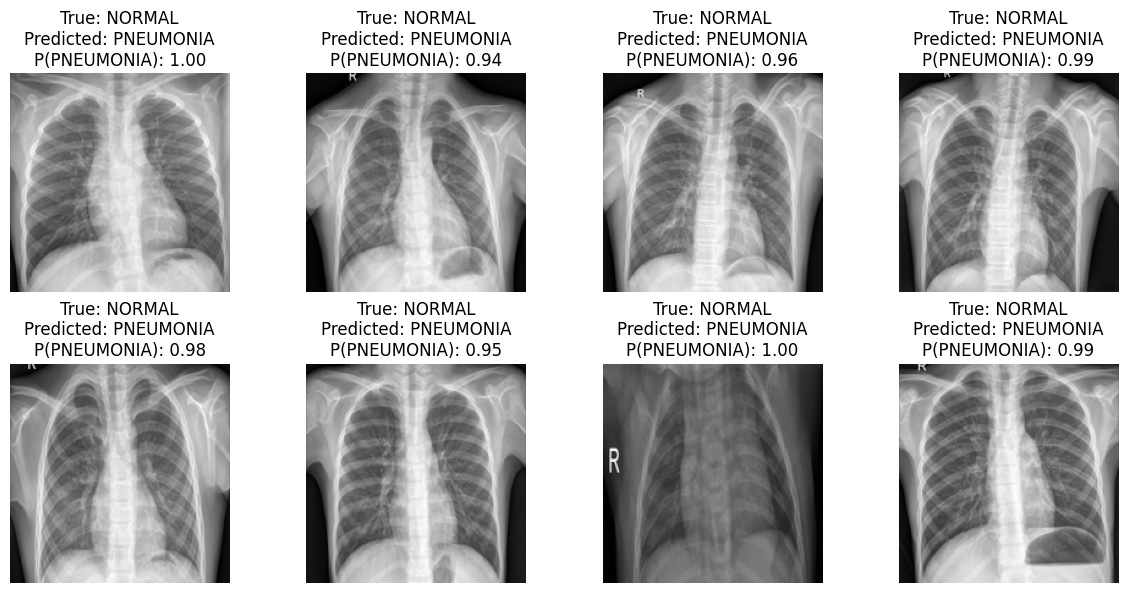

In [ ]:
wrong_indices = np.where(test_predictions != y_test)[0][:8]

if len(wrong_indices) == 0:
    print("No incorrect predictions at this threshold.")
else:
    plt.figure(figsize=(12, 6))
    for plot_number, index in enumerate(wrong_indices, start=1):
        plt.subplot(2, 4, plot_number)
        plt.imshow(X_test[index].squeeze(), cmap="gray")
        plt.title(
            f"True: {CLASSES[y_test[index]]}\n"
            f"Predicted: {CLASSES[test_predictions[index]]}\n"
            f"P(PNEUMONIA): {test_probabilities[index]:.2f}"
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()


## 15. Basic MLflow tracking (optional)

MLflow records a run each time this cell is executed. `set_experiment` chooses where runs are grouped; `start_run` creates a named run; `log_params` stores settings; `log_metrics` stores the training and validation numbers from the best validation-loss epoch. No metrics are made up: the values come from the histories above. MLflow was not installed when this notebook was prepared.

In [ ]:
try:
    import mlflow
except ImportError:
    print("MLflow is not installed. Install it with: pip install mlflow")
else:
    mlflow.set_experiment("ChestScan_AI")

    with mlflow.start_run(run_name="Transfer Learning"):
        mlflow.log_params({
            "architecture": "MobileNetV2",
            "image_size": "224x224x3",
            "augmentation": "shared offline-augmented balanced training data",
            "batch_size": BATCH_SIZE,
            "learning_rate": 0.001,
            "epochs": EPOCHS,
            "training": "frozen ImageNet base",
        })
        mlflow.log_metrics({
            "train_loss": float(transfer_history.history["loss"][transfer_best_epoch]),
            "validation_loss": float(transfer_history.history["val_loss"][transfer_best_epoch]),
            "train_accuracy": float(transfer_history.history["accuracy"][transfer_best_epoch]),
            "validation_accuracy": float(transfer_history.history["val_accuracy"][transfer_best_epoch]),
            "validation_auc": float(transfer_history.history["val_auc"][transfer_best_epoch]),
            "test_accuracy": test_metrics_by_model["Transfer Learning"]["accuracy"],
            "test_precision": test_metrics_by_model["Transfer Learning"]["precision"],
            "test_recall": test_metrics_by_model["Transfer Learning"]["recall"],
            "test_f1": test_metrics_by_model["Transfer Learning"]["f1"],
            "test_roc_auc": test_metrics_by_model["Transfer Learning"]["roc_auc"],
        })
        mlflow.log_artifact(str(TRANSFER_MODEL_PATH))

    with mlflow.start_run(run_name="Fine-tuning"):
        mlflow.log_params({
            "architecture": "MobileNetV2",
            "image_size": "224x224x3",
            "augmentation": "shared offline-augmented balanced training data",
            "batch_size": BATCH_SIZE,
            "learning_rate": 0.00001,
            "epochs": EPOCHS,
            "training": "last 30 layers fine-tuned; Batch Normalization frozen",
        })
        mlflow.log_metrics({
            "train_loss": float(finetune_history.history["loss"][finetune_best_epoch]),
            "validation_loss": float(finetune_history.history["val_loss"][finetune_best_epoch]),
            "train_accuracy": float(finetune_history.history["accuracy"][finetune_best_epoch]),
            "validation_accuracy": float(finetune_history.history["val_accuracy"][finetune_best_epoch]),
            "validation_auc": float(finetune_history.history["val_auc"][finetune_best_epoch]),
            "test_accuracy": test_metrics_by_model["Fine-tuning"]["accuracy"],
            "test_precision": test_metrics_by_model["Fine-tuning"]["precision"],
            "test_recall": test_metrics_by_model["Fine-tuning"]["recall"],
            "test_f1": test_metrics_by_model["Fine-tuning"]["f1"],
            "test_roc_auc": test_metrics_by_model["Fine-tuning"]["roc_auc"],
        })
        mlflow.log_artifact(str(FINETUNE_MODEL_PATH))

    with mlflow.start_run(run_name="Custom CNN"):
        mlflow.log_params({
            "architecture": "Custom CNN",
            "image_size": "180x180x1",
            "augmentation": "shared offline-augmented balanced training data",
            "batch_size": BATCH_SIZE,
            "learning_rate": 0.001,
            "epochs": len(custom_cnn_history.history["loss"]),
            "training": "three convolution blocks with data augmentation and class weights",
        })
        mlflow.log_metrics({
            "train_loss": float(custom_cnn_history.history["loss"][custom_cnn_best_epoch]),
            "validation_loss": float(custom_cnn_history.history["val_loss"][custom_cnn_best_epoch]),
            "train_accuracy": float(custom_cnn_history.history["accuracy"][custom_cnn_best_epoch]),
            "validation_accuracy": float(custom_cnn_history.history["val_accuracy"][custom_cnn_best_epoch]),
            "validation_auc": float(custom_cnn_val_auc),
            "test_accuracy": custom_cnn_test_metrics["accuracy"],
            "test_precision": custom_cnn_test_metrics["precision"],
            "test_recall": custom_cnn_test_metrics["recall"],
            "test_f1": custom_cnn_test_metrics["f1"],
            "test_roc_auc": custom_cnn_test_metrics["roc_auc"],
        })
        mlflow.log_artifact(str(CUSTOM_CNN_MODEL_PATH))

    print("All three runs are available in the MLflow experiment named ChestScan_AI.")


2026/10/28 10:17:06 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/28 10:17:06 INFO mlflow.store.db.utils: Updating database tables
2026/10/28 10:17:09 INFO mlflow.tracking.fluent: Experiment with name 'ChestScan_AI' does not exist. Creating a new experiment.


All three runs are available in the MLflow experiment named ChestScan_AI.


## 16. Single-image prediction

This small example repeats the same grayscale-to-RGB resize and MobileNetV2 preprocessing used above. It loads the selected model and uses the threshold chosen on validation data. The separate Streamlit app provides a simple upload screen.

In [ ]:
def predict_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("L")
        image = image.resize(IMG_SIZE)
        image_array = np.asarray(image, dtype=np.float32) / 255.0

    image_array = image_array[np.newaxis, ..., np.newaxis]
    image_array = prepare_for_mobilenet(image_array)
    probability = float(best_model.predict(image_array, verbose=0)[0][0])
    prediction = CLASSES[int(probability >= selected_threshold)]

    print("Prediction:", prediction)
    print("P(NORMAL):", round(1.0 - probability, 4))
    print("P(PNEUMONIA):", round(probability, 4))

# Example:
# predict_image("path/to/chest_xray.jpg")


## 17. Important notes

- Transfer Learning and Fine-tuning are separate runs with separate best checkpoints.
- `ModelCheckpoint` saves the best validation-loss epoch. Do not call `model.save()` afterward: that could replace the best checkpoint with the last epoch.
- The original custom CNN, stored outputs, and earlier MobileNet experiments are still available in `original_notebook_backup.ipynb`.
- The previous notebook used the test set for repeated comparisons, so the current test metrics are exploratory. A new independent dataset is needed for an unbiased final estimate.
- This model is an educational prototype, not a medical diagnosis or clinically validated tool.